# 10 - How early can the lifetime be predicted?

Everything so far used the first 100 cycles. A test lab would like to know sooner. This notebook repeats the two models with less data: the first 20, 40, 60, 80 and 100 cycles.

For a cutoff of N cycles:

- ΔQ is the discharge curve at cycle N minus the one at cycle 10
- the summary features use cycles 2 to N only (resistance change is cycle N minus cycle 2, and so on)

The models are the same two as before, with the same recipe at every cutoff: the straight line on log10(var(ΔQ)) and the Elastic Net on six features. Each cutoff gets the same cross-validation as notebook 08, on the training cells.

The primary test scores are shown next to the cross-validation numbers. They are only there to describe what happens. The model for the rest of the project stays the 100-cycle Elastic Net from notebook 08, whatever this shows. The later batch is still untouched.

This notebook reads the raw files again, because the ΔQ curves for the shorter cutoffs were not saved before.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

from src.features import delta_q_all, log_var, summary_features
from src.models import elastic_net, rmse

cells = pd.read_csv("../data/cells_clean.csv", index_col="cell_id")
cycles = pd.read_parquet("../data/cycles_clean.parquet")

CUTOFFS = [20, 40, 60, 80, 100]
ALL = ["log_var", "q2", "q_max_minus_q2", "ir_change", "charge_time_first5", "t_avg_mean"]

## Features for every cutoff

In [2]:
tables = {}
for n in CUTOFFS:
    curves, _ = delta_q_all(set(cells.index), root="../", first=10, last=n)
    feats = summary_features(cycles, last=n)
    feats.insert(0, "log_var", log_var(curves))
    tables[n] = cells[["split", "cycle_life"]].join(feats)
    print(f"first {n:3d} cycles: {tables[n].shape[0]} cells, missing values {int(tables[n].isna().sum().sum())}")

first  20 cycles: 124 cells, missing values 0
first  40 cycles: 124 cells, missing values 0
first  60 cycles: 124 cells, missing values 0


first  80 cycles: 124 cells, missing values 0
first 100 cycles: 124 cells, missing values 0


In [3]:
# at 100 cycles this has to give exactly the features from notebook 07
saved = pd.read_csv("../data/features_stage3.csv", index_col="cell_id")
pd.testing.assert_frame_equal(tables[100][ALL], saved.loc[tables[100].index, ALL], check_names=False)
print("100-cycle features match notebook 07")

100-cycle features match notebook 07


## How strong is each feature at each cutoff? (training cells)

In [4]:
corr = {}
for n in CUTOFFS:
    train = tables[n][tables[n]["split"] == "train"]
    corr[n] = train[ALL].corrwith(np.log10(train["cycle_life"]))
pd.DataFrame(corr).round(2)

,20,40,60,80,100
log_var,-0.24,-0.77,-0.89,-0.89,-0.90
q2,0.33,0.33,0.33,0.33,0.33
q_max_minus_q2,0.15,0.09,0.12,0.15,0.15
ir_change,0.48,0.49,0.37,0.36,0.38
charge_time_first5,0.77,0.77,0.77,0.77,0.77
t_avg_mean,-0.03,-0.06,-0.05,-0.05,-0.06


## Cross-validation and test score at each cutoff

In [5]:
MODELS = {
    "B: log_var line": (["log_var"], lambda: LinearRegression()),
    "D: Elastic Net": (ALL, elastic_net),
}
cv = RepeatedKFold(n_splits=5, n_repeats=20, random_state=0)


rows, coefs = [], {}
for n in CUTOFFS:
    train = tables[n][tables[n]["split"] == "train"]
    test = tables[n][tables[n]["split"] == "test_primary"]
    y = np.log10(train["cycle_life"].values)
    for name, (cols, make_model) in MODELS.items():
        X = train[cols].values
        folds = []
        for fit_idx, val_idx in cv.split(X):
            model = make_model().fit(X[fit_idx], y[fit_idx])
            folds.append(rmse(train["cycle_life"].values[val_idx], 10 ** model.predict(X[val_idx])))
        model = make_model().fit(X, y)
        pred = 10 ** model.predict(test[cols].values)
        rows.append({
            "cycles used": n, "model": name,
            "CV RMSE": np.mean(folds), "CV spread (sd)": np.std(folds),
            "test RMSE": rmse(test["cycle_life"].values, pred),
            "test MAPE (%)": np.mean(np.abs(pred - test["cycle_life"].values) / test["cycle_life"].values) * 100,
        })
        if name == "D: Elastic Net":
            coefs[n] = pd.Series(model[-1].coef_, index=ALL)

results = pd.DataFrame(rows)
results.pivot(index="cycles used", columns="model", values=["CV RMSE", "test RMSE"]).round(1)

CV RMSE                      test RMSE               
model       B: log_var line D: Elastic Net B: log_var line D: Elastic Net
cycles used                                                              
20                    299.3          196.7           386.6          204.9
40                    190.3          146.3           224.8          153.5
60                    122.3           84.7           227.8          186.7
80                    118.5           89.2           213.5          171.0
100                   108.0           81.6           137.9          113.7

In [6]:
results.pivot(index="cycles used", columns="model", values=["CV spread (sd)", "test MAPE (%)"]).round(1)

CV spread (sd)                  test MAPE (%)               
model       B: log_var line D: Elastic Net B: log_var line D: Elastic Net
cycles used                                                              
20                    166.9           94.5            31.9           24.1
40                     66.6           60.0            23.4           17.9
60                     24.9           18.3            15.7           14.1
80                     23.5           19.3            14.8           12.3
100                    18.9           16.7            14.7           12.8

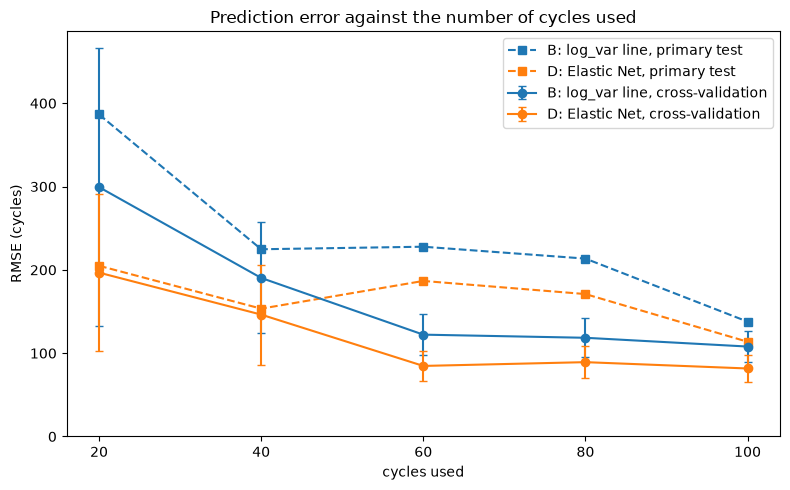

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"B: log_var line": "tab:blue", "D: Elastic Net": "tab:orange"}
for name, d in results.groupby("model"):
    ax.errorbar(d["cycles used"], d["CV RMSE"], yerr=d["CV spread (sd)"], color=colors[name], marker="o", capsize=3, label=f"{name}, cross-validation")
    ax.plot(d["cycles used"], d["test RMSE"], color=colors[name], marker="s", linestyle="--", label=f"{name}, primary test")
ax.set_xticks(CUTOFFS)
ax.set_xlabel("cycles used")
ax.set_ylabel("RMSE (cycles)")
ax.set_ylim(0, None)
ax.set_title("Prediction error against the number of cycles used")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/how_early.png", dpi=120)
plt.show()

## Why is the test error so much higher than cross-validation at 60 and 80 cycles?

The percentage error on the test set hardly changes between 60 and 100 cycles, but the RMSE does. RMSE is in cycles, so a few long-lived cells can dominate it. Split the test set the same way as in notebook 09: the three cells above 1,500 cycles, and the other 40.

In [8]:
rows = []
for n in CUTOFFS:
    train = tables[n][tables[n]["split"] == "train"]
    test = tables[n][tables[n]["split"] == "test_primary"]
    model = elastic_net().fit(train[ALL].values, np.log10(train["cycle_life"].values))
    pred = pd.Series(10 ** model.predict(test[ALL].values), index=test.index)
    long_cells = test["cycle_life"] > 1500
    row = {"cycles used": n,
           "RMSE, 3 cells above 1,500": rmse(test["cycle_life"][long_cells], pred[long_cells]),
           "RMSE, other 40 cells": rmse(test["cycle_life"][~long_cells], pred[~long_cells])}
    for cell in ["b1c0", "b1c2", "b1c4"]:
        row[f"{cell} predicted"] = pred[cell]
    rows.append(row)
print("actual lives: b1c0 1,852, b1c2 2,237, b1c4 1,709")
pd.DataFrame(rows).set_index("cycles used").round(0).astype(int)

actual lives: b1c0 1,852, b1c2 2,237, b1c4 1,709


,"RMSE, 3 cells above 1,500","RMSE, other 40 cells",b1c0 predicted,b1c2 predicted,b1c4 predicted
cycles used,,,,,
20,564,146,1505,1588,1067
40,428,108,1882,1501,1636
60,651,76,2748,1581,1517
80,591,72,2680,1661,1536
100,329,76,2078,1756,1502


In [9]:
# the same three cells in feature space: their log_var at each cutoff, next to the training range
rows = []
for n in CUTOFFS:
    t = tables[n]
    train = t[t["split"] == "train"]
    rows.append({"cycles used": n, "train min": train["log_var"].min(), "train median": train["log_var"].median(),
                 "b1c0": t.loc["b1c0", "log_var"], "b1c2": t.loc["b1c2", "log_var"], "b1c4": t.loc["b1c4", "log_var"]})
pd.DataFrame(rows).set_index("cycles used").round(2)

,train min,train median,b1c0,b1c2,b1c4
cycles used,,,,,
20,-6.44,-5.53,-6.11,-4.84,-6.16
40,-5.75,-4.66,-5.77,-5.35,-5.74
60,-5.62,-4.09,-5.97,-5.15,-5.16
80,-5.12,-3.81,-5.47,-4.80,-4.82
100,-5.01,-3.62,-5.01,-4.74,-4.65


## What the Elastic Net relies on at each cutoff

Coefficients on scaled features, fitted on all training cells.

In [10]:
pd.DataFrame(coefs).round(3)

,20,40,60,80,100
log_var,-0.000,-0.086,-0.117,-0.114,-0.115
q2,0.023,0.039,0.029,0.028,0.028
q_max_minus_q2,-0.000,-0.026,-0.025,-0.023,-0.020
ir_change,0.029,0.004,0.000,-0.000,0.000
charge_time_first5,0.105,0.062,0.032,0.037,0.034
t_avg_mean,0.000,-0.003,-0.002,-0.000,-0.000


## Save

In [11]:
results.round(2).to_csv("../reports/how_early_results.csv", index=False)
print("saved", len(results), "rows")

saved 10 rows


## Notes

- ΔQ needs time to show up. On the training cells, log_var has a correlation of only -0.24 with log cycle life after 20 cycles, -0.77 after 40, and -0.89 after 60. After that it barely moves (-0.90 at 100).
- Cross-validation follows the same pattern. The Elastic Net goes from 196.7 cycles (20 cycles used) to 146.3 (40) to 84.7 (60), and then stays there: 89.2 at 80 and 81.6 at 100. With a spread of about 17 to 19 cycles between folds, 60, 80 and 100 can't be told apart. The straight line behaves the same way, and from 60 cycles on it sits about 25 to 40 cycles higher.
- At 20 cycles the Elastic Net gives log_var a weight of exactly 0 and leans on charge time instead (0.105). So that early it isn't reading the cell at all, it is mostly guessing from the charging policy. Its error there (196.7, with a spread of 94.5) is still better than the mean baseline from notebook 08 (296.8), but not by a safe margin.
- The test set seems to disagree at 60 and 80 cycles: 186.7 and 171.0, far above cross-validation. Almost all of that is one cell. b1c0 lives 1,852 cycles and is predicted at 2,748 and 2,680. At 60 cycles its log_var is -5.97, lower than any training cell (lowest: -5.62), so the model has to extrapolate, and in log space that turns into hundreds of cycles.
- Without the three cells above 1,500 cycles, the test error is 76, 72 and 76 cycles at 60, 80 and 100 cycles. That matches cross-validation. The percentage error tells the same story: 14.1%, 12.3% and 12.8%.
- So for typical cells, 60 cycles look like enough, which would cut the test time before a prediction by 40%. For cells that turn out to live very long, the early prediction is not reliable, and waiting until cycle 100 helped (RMSE on those three: 651 at 60 cycles, 329 at 100).
- This rests on 41 training cells and 43 test cells, and the long-lived group is three cells. It's a pattern worth knowing about, not a proven rule.
- Nothing changes because of this notebook. The model stays the 100-cycle Elastic Net chosen in notebook 08.
